In [ ]:
import pandas as pd
import numpy as np
import sklearn
import matplotlib
import seaborn as sns
print("pandas", pd.__version__)
print("scikit-learn", sklearn.__version__)
print("Tout est prêt ✅")

pandas 2.2.3
scikit-learn 1.6.1
Tout est prêt ✅


In [ ]:
URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
COLUMNS = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
           "Insulin", "BMI", "DiabetesPedigreeFunction", "Age", "Outcome"]

df = pd.read_csv(URL, names=COLUMNS)
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [ ]:
print(df.shape)
print(df["Outcome"].value_counts(normalize=True).round(3))

(768, 9)
Outcome
0    0.651
1    0.349
Name: proportion, dtype: float64


je verras environ 65 % de non-diabétiques / 35 % de diabétiques → c’est ce qu’on appelle un déséquilibre modéré.


In [ ]:
df.describe().round(2)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.00,768.00,768.00,768.00,768.00,768.00,768.00,768.00,768.00
mean,3.85,120.89,69.11,20.54,79.80,31.99,0.47,33.24,0.35
std,3.37,31.97,19.36,15.95,115.24,7.88,0.33,11.76,0.48
min,0.00,0.00,0.00,0.00,0.00,0.00,0.08,21.00,0.00
25%,1.00,99.00,62.00,0.00,0.00,27.30,0.24,24.00,0.00
50%,3.00,117.00,72.00,23.00,30.50,32.00,0.37,29.00,0.00
75%,6.00,140.25,80.00,32.00,127.25,36.60,0.63,41.00,1.00
max,17.00,199.00,122.00,99.00,846.00,67.10,2.42,81.00,1.00


minimum = 0. Or un glucose à 0 ou un IMC à 0, ce n’est pas physiologiquement possible → ce sont des valeurs manquantes déguisées.

In [ ]:
cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
df[cols] = df[cols].replace(0, np.nan)
df.isna().sum()

,0
Pregnancies,0
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11
DiabetesPedigreeFunction,0
Age,0
Outcome,0


Glucose =5/ BloodPressure=35/ SkinThickness=227/INSULIN= 374/ BMI= 11/



In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, classification_report

X = df.drop(columns=["Outcome"])
y = df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced"))
])
pipe.fit(X_train, y_train)

y_proba = pipe.predict_proba(X_test)[:, 1]
print("AUC :", round(roc_auc_score(y_test, y_proba), 3))
print(classification_report(y_test, (y_proba >= 0.5).astype(int)))

AUC : 0.813
              precision    recall  f1-score   support

           0       0.82      0.75      0.79       100
           1       0.60      0.70      0.65        54

    accuracy                           0.73       154
   macro avg       0.71      0.73      0.72       154
weighted avg       0.75      0.73      0.74       154



Comparer plusieurs modèles

In [ ]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import roc_auc_score, accuracy_score,f1_score, precision_score, recall_score
import pandas as pd



In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


Ce que tu regardes :

L’AUC (capacité globale à séparer malades / non malades).

Le Recall (sensibilité) : la capacité à détecter les vrais malades. C’est la métrique clé en santé.

Tu ne choisis pas forcément le modèle avec la meilleure accuracy, mais celui qui a le meilleur compromis AUC + Recall.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score)
import pandas as pd

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "LogisticRegression": (
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("clf", LogisticRegression(class_weight="balanced", max_iter=1000))
        ]),
        {"clf__C": [0.01, 0.1, 1, 10]},          # ← double underscore
    ),
    "RandomForest": (
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("clf", RandomForestClassifier(random_state=42, class_weight="balanced"))
        ]),
        {"clf__n_estimators": [200, 400],         # ← double underscore
         "clf__max_depth": [None, 5, 10]},        # ← double underscore
    ),
    "GradientBoosting": (
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("clf", GradientBoostingClassifier(random_state=42))
        ]),
        {"clf__n_estimators": [100, 200],         # ← double underscore
         "clf__learning_rate": [0.05, 0.1]},      # ← double underscore
    ),
    "SVM": (
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("clf", SVC(probability=True, random_state=42, class_weight="balanced"))
        ]),
        {"clf__C": [0.1, 1, 10],                  # ← double underscore
         "clf__kernel": ["linear", "rbf"]},       # ← double underscore
    ),
}

results = []
best_models = {}

for name, (pipe, grid) in models.items():
    search = GridSearchCV(pipe, grid, cv=cv, scoring="roc_auc", n_jobs=-1)
    search.fit(X_train, y_train)
    best = search.best_estimator_
    best_models[name] = best

    y_proba = best.predict_proba(X_test)[:, 1]
    y_pred = (y_proba >= 0.5).astype(int)

    results.append({
        "model": name,
        "auc_test": round(roc_auc_score(y_test, y_proba), 4),
        "accuracy": round(accuracy_score(y_test, y_pred), 4),
        "precision": round(precision_score(y_test, y_pred), 4),
        "recall": round(recall_score(y_test, y_pred), 4),
        "f1": round(f1_score(y_test, y_pred), 4),
    })

results_df = pd.DataFrame(results).sort_values("auc_test", ascending=False)
print(results_df.to_string(index=False))

             model  auc_test  accuracy  precision  recall     f1
  GradientBoosting    0.8228    0.7403     0.6591  0.5370 0.5918
      RandomForest    0.8180    0.7403     0.6094  0.7222 0.6610
LogisticRegression    0.8104    0.7078     0.5714  0.6667 0.6154
               SVM    0.8065    0.7078     0.6000  0.5000 0.5455


L’AUC (capacité globale à séparer malades / non malades).

Le Recall (sensibilité) : la capacité à détecter les vrais malades. C’est la métrique clé en santé.

Tu ne choisis pas forcément le modèle avec la meilleure accuracy, mais celui qui a le meilleur compromis AUC + Recall.

Ajuster le seuil de décision (LA partie qui impressionne)

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    precision_score, recall_score, f1_score, confusion_matrix
)

# --- 1. Sélection automatique du modèle final ---
candidats = results_df[(results_df["recall"] >= 0.70) &
                       (results_df["precision"] >= 0.50)]

if len(candidats) == 0:
    print("⚠️ Aucun modèle ne passe les filtres, on prend le meilleur AUC.")
    candidats = results_df

final_row = candidats.sort_values("auc_test", ascending=False).iloc[0]
final_name = final_row["model"]
print(f"✅ Modèle final retenu : {final_name}")
print(final_row.to_string())

# --- LOOKUP ROBUSTE (remplace best_models[final_name]) ---
key_map = {k.lower(): k for k in best_models.keys()}
final_key = key_map.get(final_name.lower())
if final_key is None:
    raise KeyError(
        f"'{final_name}' absent de best_models. "
        f"Clés disponibles : {list(best_models.keys())}."
    )
final_model = best_models[final_key]

y_proba = final_model.predict_proba(X_test)[:, 1]

# --- 2. Tableau des seuils ---
rows = []
for t in np.arange(0.20, 0.81, 0.05):
    y_pred_t = (y_proba >= t).astype(int)
    rows.append({
        "Seuil": round(t, 2),
        "Precision": round(precision_score(y_test, y_pred_t, zero_division=0), 3),
        "Recall": round(recall_score(y_test, y_pred_t, zero_division=0), 3),
        "F1": round(f1_score(y_test, y_pred_t, zero_division=0), 3),
    })

seuils_df = pd.DataFrame(rows)
print("\n=== Effet du seuil de décision ===")
print(seuils_df.to_string(index=False))

✅ Modèle final retenu : RandomForest
model        RandomForest
auc_test            0.818
accuracy           0.7403
precision          0.6094
recall             0.7222
f1                  0.661

=== Effet du seuil de décision ===
 Seuil  Precision  Recall    F1
  0.20      0.468   0.963 0.630
  0.25      0.526   0.944 0.675
  0.30      0.533   0.889 0.667
  0.35      0.540   0.870 0.667
  0.40      0.570   0.833 0.677
  0.45      0.589   0.796 0.677
  0.50      0.609   0.722 0.661
  0.55      0.636   0.648 0.642
  0.60      0.600   0.500 0.545
  0.65      0.676   0.463 0.549
  0.70      0.697   0.426 0.529
  0.75      0.762   0.296 0.427
  0.80      0.833   0.185 0.303


In [ ]:
# --- 3. Choix du seuil : recall max avec precision >= 0.55 ---
ok = seuils_df[seuils_df["Precision"] >= 0.55]

if len(ok) > 0:
    best_thr_row = ok.sort_values(["Recall", "F1"], ascending=False).iloc[0]
else:
    best_thr_row = seuils_df.sort_values(["Recall", "F1"], ascending=False).iloc[0]

seuil_choisi = best_thr_row["Seuil"]
print(f"✅ Seuil retenu : {seuil_choisi}  "
      f"(precision = {best_thr_row['Precision']}, "
      f"recall = {best_thr_row['Recall']}, "
      f"f1 = {best_thr_row['F1']})")

# --- 4. Matrices de confusion ---
y_pred_05 = (y_proba >= 0.5).astype(int)
y_pred_final = (y_proba >= seuil_choisi).astype(int)

print("\n=== Matrice de confusion — seuil 0.50 ===")
print(confusion_matrix(y_test, y_pred_05))

print(f"\n=== Matrice de confusion — seuil {seuil_choisi} ===")
print(confusion_matrix(y_test, y_pred_final))

tn, fp, fn, tp = confusion_matrix(y_test, y_pred_final).ravel()
print(f"\nVrais négatifs : {tn}")
print(f"Faux positifs  : {fp}")
print(f"Faux négatifs  : {fn}   ← ce qu'on veut minimiser")
print(f"Vrais positifs : {tp}")

✅ Seuil retenu : 0.4  (precision = 0.57, recall = 0.833, f1 = 0.677)

=== Matrice de confusion — seuil 0.50 ===
[[75 25]
 [15 39]]

=== Matrice de confusion — seuil 0.4 ===
[[66 34]
 [ 9 45]]

Vrais négatifs : 66
Faux positifs  : 34
Faux négatifs  : 9   ← ce qu'on veut minimiser
Vrais positifs : 45


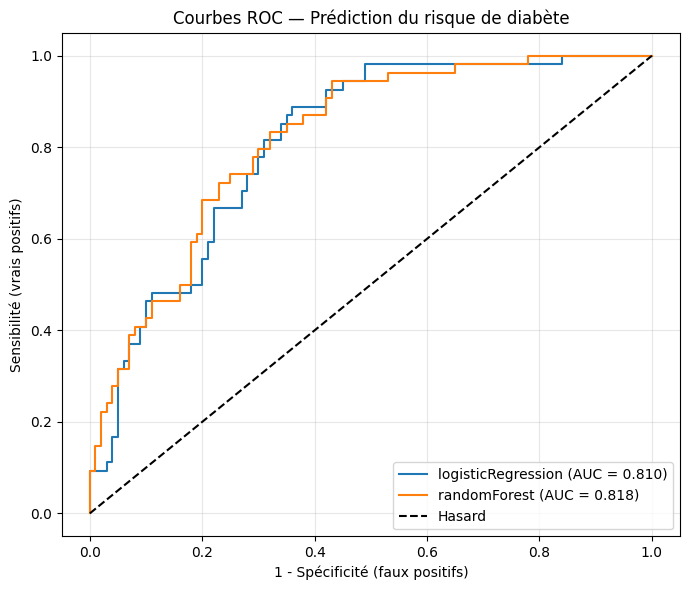

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

plt.figure(figsize=(7, 6))
for name, model in best_models.items():
    p = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, p)
    auc = roc_auc_score(y_test, p)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Hasard")
plt.xlabel("1 - Spécificité (faux positifs)")
plt.ylabel("Sensibilité (vrais positifs)")
plt.title("Courbes ROC — Prédiction du risque de diabète")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("roc_curves.png", dpi=150)
plt.show()

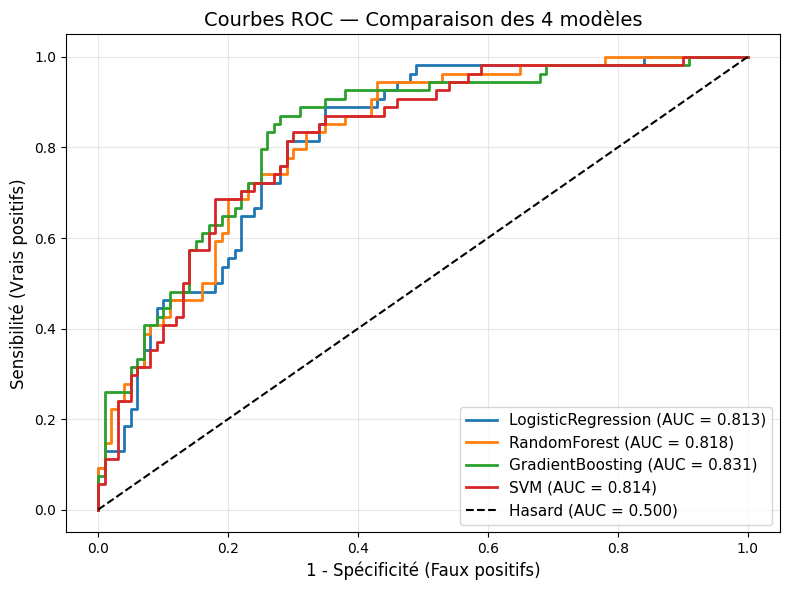

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC

# 1. On redéfinit et on entraîne rapidement les 4 modèles
# (on utilise les hyperparamètres par défaut ou ceux trouvés pour aller vite)
models_rocs = {
    "LogisticRegression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(class_weight="balanced", max_iter=1000, C=1))
    ]),
    "RandomForest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("clf", RandomForestClassifier(random_state=42, class_weight="balanced", n_estimators=200, max_depth=5))
    ]),
    "GradientBoosting": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("clf", GradientBoostingClassifier(random_state=42, n_estimators=100, learning_rate=0.1))
    ]),
    "SVM": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("clf", SVC(probability=True, random_state=42, class_weight="balanced", C=1, kernel="rbf"))
    ])
}

# 2. Entraînement sur le jeu d'entraînement
for name, model in models_rocs.items():
    model.fit(X_train, y_train)

# 3. Tracé de la courbe ROC avec les 4 modèles
plt.figure(figsize=(8, 6))

for name, model in models_rocs.items():
    y_proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc = roc_auc_score(y_test, y_proba)

    # On trace chaque courbe
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})", linewidth=2)

# Diagonale du hasard
plt.plot([0, 1], [0, 1], "k--", label="Hasard (AUC = 0.500)")

plt.xlabel("1 - Spécificité (Faux positifs)", fontsize=12)
plt.ylabel("Sensibilité (Vrais positifs)", fontsize=12)
plt.title("Courbes ROC — Comparaison des 4 modèles", fontsize=14)
plt.legend(loc="lower right", fontsize=11)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("roc_curves_4_modeles.png", dpi=150)
plt.show()

=== Importance des variables ===
Glucose                     0.337
BMI                         0.181
Age                         0.126
Insulin                     0.112
DiabetesPedigreeFunction    0.075
Pregnancies                 0.060
SkinThickness               0.060
BloodPressure               0.049
dtype: float64


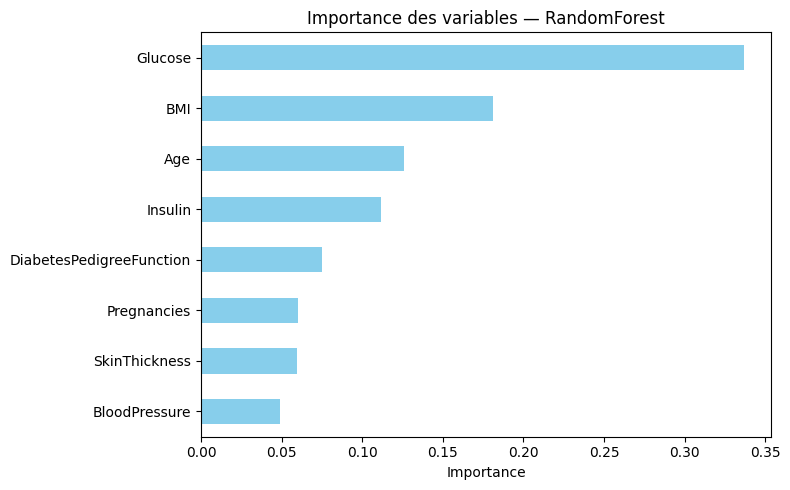

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

clf_final = final_model.named_steps["clf"]

if hasattr(clf_final, "feature_importances_"):
    importances = pd.Series(clf_final.feature_importances_,
                            index=X.columns).sort_values(ascending=False)
    print("=== Importance des variables ===")
    print(importances.round(3))

    plt.figure(figsize=(8, 5))
    importances.plot(kind="barh", color="skyblue")
    plt.gca().invert_yaxis()
    plt.title(f"Importance des variables — {final_name}")
    plt.xlabel("Importance")
    plt.tight_layout()
    plt.savefig("feature_importance.png", dpi=150)
    plt.show()

elif hasattr(clf_final, "coef_"):
    coefs = pd.Series(clf_final.coef_[0], index=X.columns).sort_values()
    print("=== Coefficients (log-odds) ===")
    print(coefs.round(3))

    plt.figure(figsize=(8, 5))
    coefs.plot(kind="barh", color="salmon")
    plt.title(f"Coefficients — {final_name}")
    plt.xlabel("Log-odds")
    plt.tight_layout()
    plt.savefig("feature_importance.png", dpi=150)
    plt.show()